PHASE 8 : SCORECARD

In [18]:
# restoring saved features

import joblib
import json
import pandas as pd
import numpy as np

# Charger le modèle sklearn (pour les coefficients)
model = joblib.load("../models/logistic_model.pkl")

# Charger la liste des features retenues
with open("../models/selected_features.json") as f:
    selected_features = json.load(f)

# Charger les données WoE
X_train_woe = pd.read_parquet("../data/processed/X_train_woe.parquet")
X_test_woe = pd.read_parquet("../data/processed/X_test_woe.parquet")


y_train = pd.read_parquet("../data/processed/y_train.parquet").squeeze()
y_test=pd.read_parquet('../data/processed/y_test.parquet').squeeze()
# Charger le binning process (pour les bins et WoE)
bp = joblib.load("../models/binning_process.pkl")

print("Features retenues :", selected_features)
print("Modèle chargé :", type(model))

Features retenues : ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_installment_plans']
Modèle chargé : <class 'sklearn.linear_model._logistic.LogisticRegression'>


8.2/ Parametrage du scaling 

In [6]:
# --- Paramètres de scaling ---
PDO = 20                          # Points to Double the Odds
BASE_SCORE = 600                  # Score de base (score médian visé)
BASE_ODDS = 20                    # Odds de base (ex. 20:1 good:bad)

# Factor : combien de points par unité de log-odds
Factor = PDO / np.log(2)          # ≈ 28.85 (si PDO=20)

# Offset : score de base ajusté
Offset = BASE_SCORE - Factor * np.log(BASE_ODDS)

print(f"PDO = {PDO}")
print(f"Factor = {Factor:.4f}")
print(f"Offset = {Offset:.4f}")

PDO = 20
Factor = 28.8539
Offset = 513.5614


8.3/ Calcul des points âr variable et par bin



In [7]:
# Récupérer les coefficients du modèle sklearn
# model.coef_ contient les β pour chaque feature
# model.intercept_ contient β₀

coef_dict = dict(zip(selected_features, model.coef_[0]))
intercept = model.intercept_[0]

print("Intercept (β₀) :", intercept)
print("Coefficients :")
for feat, coef in coef_dict.items():
    print(f"  {feat}: {coef:.4f}")

Intercept (β₀) : -0.8474334901765069
Coefficients :
  checking_status: -0.8042
  duration: -0.9085
  credit_history: -0.6678
  purpose: -0.9265
  credit_amount: -0.8608
  savings: -0.8397
  employment: -0.6857
  installment_rate: -1.3193
  personal_status_sex: -1.0866
  other_installment_plans: -0.6827


8.4/ Construre le scorecard

In [15]:
import pandas as pd


def build_scorecard(
    bp, selected_features, coef_dict, factor, offset, intercept
):
  rows = []
  n_features = len(selected_features)

  intercept_per_var = intercept / n_features
  offset_per_var = offset / n_features

  for var in selected_features:
    table = bp.get_binned_variable(var).binning_table.build()
    coef = float(coef_dict.get(var, 0.0))

    for _, row in table.iterrows():
      bin_name = str(row["Bin"])

      # 1. Ignorer la ligne "Total" et les comptes nuls
      if bin_name.lower() == "total" or row["Count"] == 0:
        continue

      raw_woe = row["WoE"]

      # 2. Vérifier si le WoE est vide, un espace ou non convertible
      if (
          raw_woe is None
          or str(raw_woe).strip() == ""
          or str(raw_woe).strip() == "nan"
      ):
        continue

      try:
        woe = float(raw_woe)
        event_rate = float(row["Event rate"])
        count = int(row["Count"])
      except (ValueError, TypeError):
        continue  # Ignore proprement si ce n'est pas un nombre

      # 3. Calcul sécurisé des points
      points = -((coef * woe + intercept_per_var) * float(factor)) + float(
          offset_per_var
      )

      rows.append({
          "variable": var,
          "bin": bin_name,
          "woe": round(woe, 4),
          "count": count,
          "event_rate": round(event_rate, 4),
          "points": round(points, 2),
      })

  scorecard_df = pd.DataFrame(rows)
  return scorecard_df


# Exécution
scorecard = build_scorecard(
    bp, selected_features, coef_dict, Factor, Offset, intercept
)
print(scorecard.to_string(index=False))

               variable                                                          bin     woe  count  event_rate  points
        checking_status                <StringArray>\n['A14']\nLength: 1, dtype: str  1.1841    276      0.1159   81.28
        checking_status                <StringArray>\n['A13']\nLength: 1, dtype: str  0.1335     44      0.2727   56.90
        checking_status                <StringArray>\n['A12']\nLength: 1, dtype: str -0.4152    188      0.3936   44.17
        checking_status                <StringArray>\n['A11']\nLength: 1, dtype: str -0.7639    192      0.4792   36.08
               duration                                                 (-inf, 8.50)  1.4553     66      0.0909   91.95
               duration                                                [8.50, 11.50)  0.4998     63      0.2063   66.90
               duration                                               [11.50, 16.50)  0.2513    180      0.2500   60.39
               duration                 

In [30]:
def calculate_score(df_woe, selected_features, scorecard, Factor, Offset, intercept):
    """Calcule le score de chaque client.
    
    Score = Offset + Factor * intercept + Σ points(variable, bin)
    
    Parameters
    ----------
    df_woe : pd.DataFrame
        Données WoE (train ou test).
    selected_features : list
        Variables retenues.
    scorecard : pd.DataFrame
        Scorecard avec les points par bin.
    Factor, Offset : float
        Paramètres de scaling.
    intercept : float
        Intercept du modèle.
    
    Returns
    -------
    pd.Series
        Score de chaque client.
    """
    # Score de base (offset + intercept converti en points)
    base_points = Offset + Factor * intercept
    
    # Pour chaque variable, mapper le WoE au points
    scores = pd.Series(base_points, index=df_woe.index)
    
    for var in selected_features:
        # Récupérer les points de cette variable
        var_card = scorecard[scorecard["variable"] == var]
        print(f'var_card : {var_card}')
        
        # Mapper chaque client à son bin et ses points
        # Le WoE de chaque client pour cette variable est dans df_woe[var]
        # On trouve le bin correspondant et on récupère les points
        
        # Méthode : pour chaque client, trouver le bin dont le WoE est le plus proche
        # (ou utiliser le binning process pour retrouver le bin)
        # Ici, on utilise une approche simplifiée : mapper WoE → points
        
        # Créer un mapping WoE → points pour cette variable
        woe_to_points = dict(zip(var_card["woe"].round(4), var_card["points"]))
        print(f"woe to point : {woe_to_points}")
        # Mapper les WoE des clients aux points
        client_woes = df_woe[var].round(4)
        print(f'client woe : {client_woes}')

        client_points = client_woes.map(woe_to_points)
        print(f"cleint point : {client_points}")
        
        scores += client_points
    
    return scores

# Calculer les scores train et test
train_scores = calculate_score(X_train_woe, selected_features, scorecard, Factor, Offset, intercept)
test_scores = calculate_score(X_test_woe, selected_features, scorecard, Factor, Offset, intercept)

print("Score train — min:", train_scores.min(), "max:", train_scores.max(), "mean:", round(train_scores.mean(),1) )
print("Score test  — min:", test_scores.min(), "max:", test_scores.max(), "mean:", round(test_scores.mean(), 1 )  )

var_card :           variable                                            bin     woe  \
0  checking_status  <StringArray>\n['A14']\nLength: 1, dtype: str  1.1841   
1  checking_status  <StringArray>\n['A13']\nLength: 1, dtype: str  0.1335   
2  checking_status  <StringArray>\n['A12']\nLength: 1, dtype: str -0.4152   
3  checking_status  <StringArray>\n['A11']\nLength: 1, dtype: str -0.7639   

   count  event_rate  points  
0    276      0.1159   81.28  
1     44      0.2727   56.90  
2    188      0.3936   44.17  
3    192      0.4792   36.08  
woe to point : {1.1841: 81.28, 0.1335: 56.9, -0.4152: 44.17, -0.7639: 36.08}
client woe : index
10    -0.4152
82     1.1841
827    1.1841
410   -0.4152
48     1.1841
        ...  
603    1.1841
759   -0.7639
298    1.1841
417   -0.7639
749    1.1841
Name: checking_status, Length: 700, dtype: float64
cleint point : index
10     44.17
82     81.28
827    81.28
410    44.17
48     81.28
       ...  
603    81.28
759    36.08
298    81.28
417    36

In [21]:
train_scores

index
10    NaN
82    NaN
827   NaN
410   NaN
48    NaN
       ..
603   NaN
759   NaN
298   NaN
417   NaN
749   NaN
Length: 700, dtype: float64

Phase 8.6 : definition de la place de scores et de distribution


=== Distribution des scores (train) ===
count     700.000000
mean     1038.454219
std        44.543034
min       918.889676
25%      1005.762176
50%      1038.024676
75%      1070.497176
max      1147.879676
dtype: float64

Percentiles train :
0.01     948.399276
0.05     968.984176
0.10     982.616676
0.25    1005.762176
0.50    1038.024676
0.75    1070.497176
0.90    1099.507676
0.95    1115.022676
0.99    1137.116276
dtype: float64


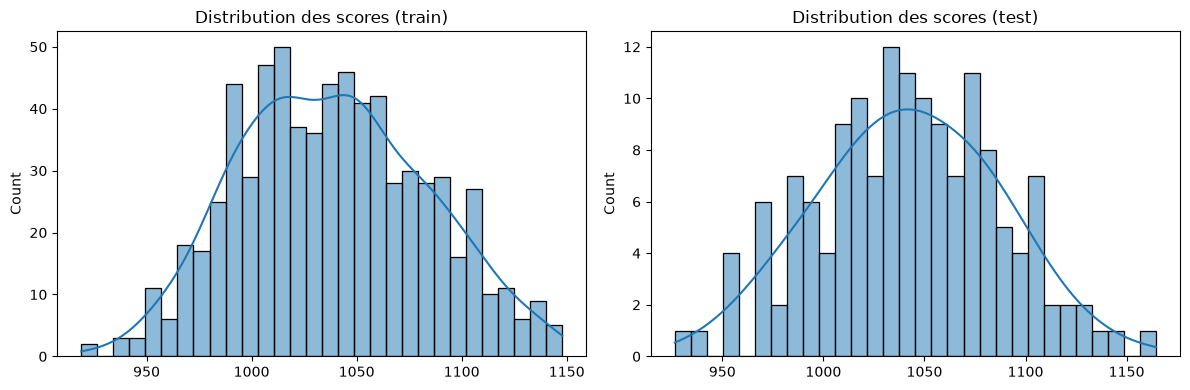

In [32]:
# Statistiques des scores
print("\n=== Distribution des scores (train) ===")
print(train_scores.describe())

# Percentiles
print("\nPercentiles train :")
print(train_scores.quantile([0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_scores, bins=30, ax=axes[0], kde=True)
axes[0].set_title("Distribution des scores (train)")
sns.histplot(test_scores, bins=30, ax=axes[1], kde=True)
axes[1].set_title("Distribution des scores (test)")
plt.tight_layout()
plt.show()

Remarques :
La adistribution est approximativement normale 
Les scores en train et en tests ojt des distributions similaires
La plage de scroes est coherente avec le BASE_SCORE (=20) choisi

8.7 / Saiuvegarde de la scirecard et des scores



In [33]:
import joblib
import json

# Sauvegarder la scorecard (tableau des points)
scorecard.to_csv("../models/scorecard.csv", index=False)
joblib.dump(scorecard, "../models/scorecard.pkl")

# Sauvegarder les paramètres de scaling
scaling_params = {
    "PDO": PDO,
    "BASE_SCORE": BASE_SCORE,
    "BASE_ODDS": BASE_ODDS,
    "Factor": Factor,
    "Offset": Offset,
    "intercept": intercept,
}
with open("../models/scaling_params.json", "w") as f:
    json.dump(scaling_params, f, indent=2)

# Sauvegarder les scores
train_scores.to_frame("score").to_parquet("../data/processed/train_scores.parquet")
test_scores.to_frame("score").to_parquet("../data/processed/test_scores.parquet")

# Sauvegarder aussi la cible avec les scores (pour la validation)
y_train.to_frame("default").join(train_scores.rename("score")).to_parquet("../data/processed/train_scores_with_target.parquet")
y_test.to_frame("default").join(test_scores.rename("score")).to_parquet("../data/processed/test_scores_with_target.parquet")

print("✅ Scorecard et scores sauvegardés")

✅ Scorecard et scores sauvegardés


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone
index,,,,,,,,,,,,,,,,,,
10,-0.415165,0.251314,-0.082842,-0.180353,0.128712,-0.301787,-0.579034,-0.100083,-0.246088,-0.071459,-0.034804,-0.587015,0.174622,-0.468861,-0.035545,0.039556,0.005666,-0.044150
82,1.184134,-0.176130,-0.082842,-0.241162,0.239754,-0.098061,0.074691,-0.100083,-0.246088,0.036368,0.051449,-0.587015,0.174622,-0.468861,-0.035545,0.104261,0.005666,-0.044150
827,1.184134,-0.176130,-1.090920,-0.241162,-0.311780,-0.301787,0.074691,0.211784,0.163420,-0.010050,-0.034804,0.264053,-0.308301,0.214468,0.060961,0.039556,-0.029853,-0.044150
410,-0.415165,-0.176130,-0.082842,0.384846,0.239754,-0.301787,0.194156,-0.149489,-0.246088,0.036368,-0.034804,-0.154151,0.174622,0.214468,-0.035545,0.039556,0.005666,0.066521
48,1.184134,0.499776,0.699082,-0.180353,-0.311780,-0.301787,0.074691,0.292136,0.163420,0.036368,0.051449,0.264053,0.174622,0.214468,0.060961,0.104261,0.005666,-0.044150
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
603,1.184134,-0.474623,-0.082842,-0.111591,0.251314,-0.301787,0.074691,-0.149489,-0.246088,-0.010050,-0.034804,-0.117337,0.174622,0.214468,-0.035545,-0.273497,0.005666,0.066521
759,-0.763916,0.251314,0.699082,-0.180353,-0.310993,-0.301787,0.194156,-0.149489,0.163420,-0.010050,0.051449,0.264053,0.174622,0.214468,0.060961,0.039556,0.005666,-0.044150
298,1.184134,-0.176130,-0.082842,-0.111591,0.239754,-0.301787,0.074691,-0.100083,0.163420,0.036368,0.471278,0.264053,0.174622,0.214468,-0.035545,0.039556,0.005666,0.066521
